# 03 · Behavioural customer segmentation
**Question:** which customer groups deserve different campaign treatment?

**Design choice:** the first version of this project clustered on macro-economic indicators too. Those describe *when* a call happened, not *who* the customer is, and produced clusters that mostly separated calendar periods (euribor 4.8 vs 1.2). Segments are now built only on customer and contact-history traits.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import data, modelling, business, segmentation
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.3f}'.format)
df = data.clean(data.load_raw())

In [2]:
diag = segmentation.diagnostics(df); diag

,k,inertia,silhouette_sample
0,2,217905.153,0.576
1,3,191342.913,0.158
2,4,169012.073,0.165
3,5,146371.310,0.184
4,6,135538.107,0.161
5,7,129621.192,0.161
6,8,124386.136,0.155


**Choosing k.** Silhouette is highest at k=2 (success vs no success: too coarse to act on) and low elsewhere (~0.16), i.e. customers form a continuum rather than crisp clusters. k=4 was chosen because it yields four *commercially distinct* groups; the segments are a practical targeting heuristic, not a claim of natural clusters.

In [3]:
seg = pd.read_csv(PROCESSED/'customer_segment_profile.csv'); seg

,segment,Customers,SubscriptionRate,AvgAge,AvgCampaign,AvgPreviousContacts,CustomerShare,Subscribers,ShareOfAllSubscribers
0,Re-engaged past successes,1531,0.634,41.880,1.826,1.687,0.037,970,0.209
1,Younger first-time prospects,23807,0.096,33.453,2.128,0.125,0.578,2295,0.495
2,Established first-time prospects,14128,0.093,50.936,2.171,0.109,0.343,1307,0.282
3,Over-contacted prospects,1722,0.039,39.692,12.556,0.024,0.042,68,0.015


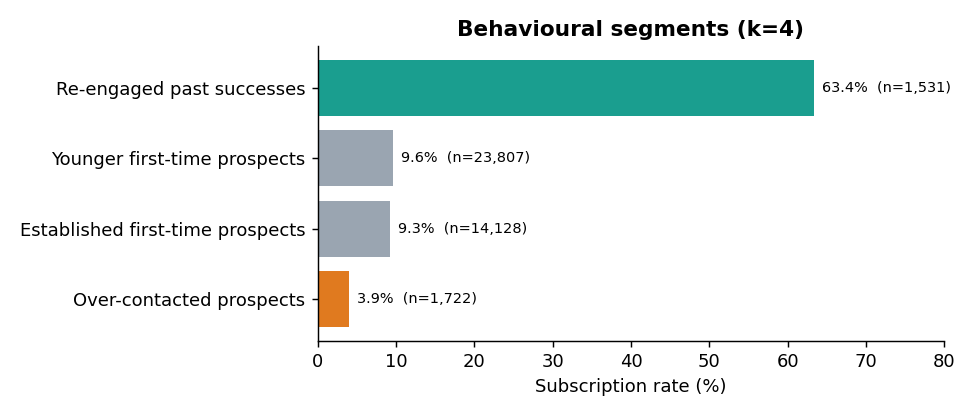

In [4]:
display(Image(IMAGES/'subscription_rate_by_segment.png', width=620))

**Segment playbook (hypotheses to A/B test)**
| Segment | Size | Rate | Suggested treatment |
|---|---|---|---|
| Re-engaged past successes | 3.7% | 63% | Priority, low-friction relationship call; 21% of all subscribers from <4% of customers |
| Younger first-time prospects | 58% | 9.6% | Scalable digital-first nurture; cellular outreach |
| Established first-time prospects | 34% | 9.3% | Standard cadence, cap attempts |
| Over-contacted prospects | 4.2% | 3.9% | Pilot a cap of ~3–4 attempts; 12.6 average calls for 1.5% of subscribers |